# TASK 1: Data Loading and Exploratory Data Analysis (EDA)

In [2]:
# ImportingPackages 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# importing dataset
student_classification = pd.read_excel("student_classification.xlsx")
print(student_classification.head(10))
print(student_classification.shape)

  Student_ID  Study_Hours_Per_Day  Attendance_Rate (%)  Previous_GPA  \
0    STU0001                  4.4                   73          1.74   
1    STU0002                  9.6                   60          2.28   
2    STU0003                  7.6                   98          3.95   
3    STU0004                  6.4                   57          1.94   
4    STU0005                  2.4                   85          1.54   
5    STU0006                  2.4                   87          3.41   
6    STU0007                  1.5                   89          3.52   
7    STU0008                  8.8                   69          2.37   
8    STU0009                  6.4                   84          2.66   
9    STU0010                  7.4                   97          3.12   

   Assignments_Completed (%)  Class_Participation (1-10)  Sleep_Hours  \
0                         86                           6          4.6   
1                         59                           4     

In [4]:
#  Showing the class distribution of the target variable (Performance_Label) 
# print(student_classification.Performance_Label.value_counts())
# print(student_classification.Performance_Label.value_counts(normalize=True) * 100)
distribution = pd.DataFrame({
    'Count': student_classification.Performance_Label.value_counts(),
    'Percentage':student_classification.Performance_Label.value_counts(normalize=True) * 100
})
print(distribution.round(2))

                   Count  Percentage
Performance_Label                   
Excellent            155        77.5
Good                  39        19.5
Average                6         3.0


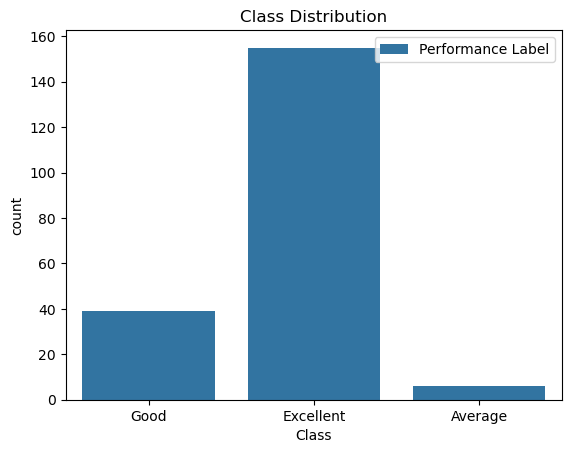

In [5]:
# ploting bar
sns.countplot(x= "Performance_Label", data = student_classification)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("count")
plt.legend(["Performance Label"]);

In [6]:
# Computing summary statistics
student_classification.describe()

,Study_Hours_Per_Day,Attendance_Rate (%),Previous_GPA,Assignments_Completed (%),Class_Participation (1-10),Sleep_Hours,Extracurricular_Activities
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,5.358500,76.640000,2.778450,75.620000,5.495000,6.315000,2.455000
std,2.655842,14.250466,0.722116,15.206967,2.756441,1.421117,1.709558
min,1.000000,50.000000,1.530000,50.000000,1.000000,4.000000,0.000000
25%,3.100000,66.000000,2.150000,63.000000,3.000000,5.075000,1.000000
50%,5.450000,77.500000,2.800000,75.000000,5.500000,6.200000,2.000000
75%,7.800000,88.000000,3.362500,89.000000,8.000000,7.425000,4.000000
max,9.900000,100.000000,3.990000,100.000000,10.000000,9.000000,5.000000


In [7]:
# Checkingfor missing values
student_classification.isnull().sum()

Student_ID                     0
Study_Hours_Per_Day            0
Attendance_Rate (%)            0
Previous_GPA                   0
Assignments_Completed (%)      0
Class_Participation (1-10)     0
Sleep_Hours                    0
Extracurricular_Activities     0
Parent_Education              13
Internet_Access                0
Tutoring_Support               0
Performance_Label              0
dtype: int64

In [8]:
# Handling missing values by imputation
mode_value = student_classification.Parent_Education.mode()[0]
student_classification.Parent_Education = student_classification.Parent_Education.fillna(mode_value)

print("Missing values after imputation:", student_classification.Parent_Education.isnull().sum())
print("Mode used:", mode_value)

Missing values after imputation: 0
Mode used: Bachelor


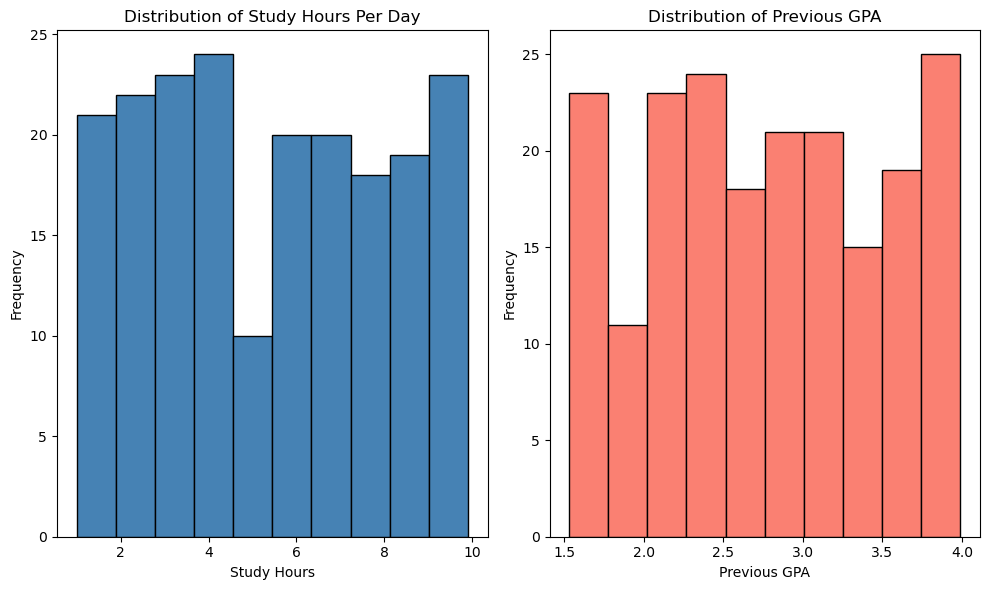

In [9]:
# Ploting histogram
plt.figure(figsize = (10,6))
plt.subplot(1, 2, 1)
plt.hist(student_classification.Study_Hours_Per_Day,bins=10, color = "SteelBlue", edgecolor="black")
plt.title("Distribution of Study Hours Per Day")
plt.xlabel("Study Hours")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(student_classification.Previous_GPA, bins=10, color='salmon', edgecolor='black')
plt.title('Distribution of Previous GPA')
plt.xlabel('Previous GPA')
plt.ylabel('Frequency')
plt.tight_layout()

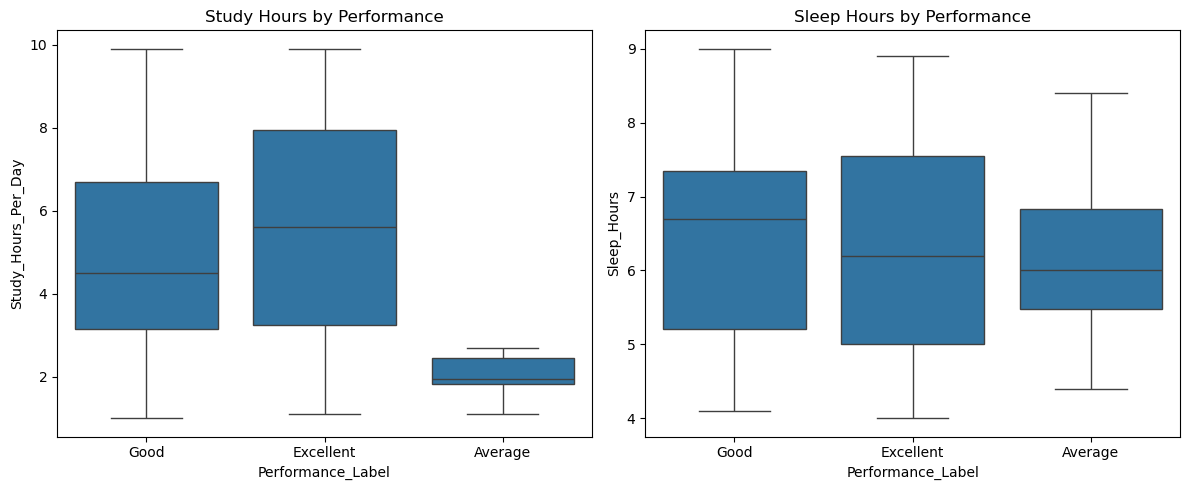

In [10]:
# Plotting Box Plots for Study Hours By Performance and Sleep hours by Performance
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Performance_Label', y='Study_Hours_Per_Day', data=student_classification)
plt.title('Study Hours by Performance')

plt.subplot(1, 2, 2)
sns.boxplot(x='Performance_Label', y='Sleep_Hours', data=student_classification)
plt.title('Sleep Hours by Performance')

plt.tight_layout()
plt.show()

# TASK 2:  Data Preprocessing

In [11]:
# Dropping Students ID
student_classification = student_classification.drop(columns=['Student_ID'])
print(student_classification.shape)
print(student_classification.columns)

(200, 11)
Index(['Study_Hours_Per_Day', 'Attendance_Rate (%)', 'Previous_GPA',
       'Assignments_Completed (%)', 'Class_Participation (1-10)',
       'Sleep_Hours', 'Extracurricular_Activities', 'Parent_Education',
       'Internet_Access', 'Tutoring_Support', 'Performance_Label'],
      dtype='object')


In [12]:
print(student_classification.Performance_Label.unique())
print(student_classification.Performance_Label.value_counts())

['Good' 'Excellent' 'Average']
Performance_Label
Excellent    155
Good          39
Average        6
Name: count, dtype: int64


In [13]:
# Encoding using Label Encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
# Encoding all 3 categorical columns
student_classification.Parent_Education = le.fit_transform(student_classification.Parent_Education)
student_classification.Internet_Access = le.fit_transform(student_classification.Internet_Access)
student_classification.Tutoring_Support = le.fit_transform(student_classification.Tutoring_Support)

# Verify
print(student_classification[['Parent_Education', 'Internet_Access', 'Tutoring_Support']].head(10))
print("\nData types after encoding:")
print(student_classification.dtypes)

   Parent_Education  Internet_Access  Tutoring_Support
0                 2                0                 0
1                 0                1                 1
2                 2                1                 0
3                 1                1                 0
4                 1                1                 0
5                 1                1                 1
6                 0                1                 1
7                 1                1                 0
8                 3                1                 0
9                 1                1                 0

Data types after encoding:
Study_Hours_Per_Day           float64
Attendance_Rate (%)             int64
Previous_GPA                  float64
Assignments_Completed (%)       int64
Class_Participation (1-10)      int64
Sleep_Hours                   float64
Extracurricular_Activities      int64
Parent_Education                int64
Internet_Access                 int64
Tutoring_Support         

In [14]:
# Separate encoder for binary columns
le = LabelEncoder()
student_classification.Internet_Access = le.fit_transform(student_classification.Internet_Access)
student_classification.Tutoring_Support = le.fit_transform(student_classification.Tutoring_Support)

# Separate encoder for target variable
le_target = LabelEncoder()
student_classification.Performance_Label = le_target.fit_transform(
    student_classification.Performance_Label)

# Mapping and decoding using le_target
label_mapping = dict(zip(le_target.classes_, le_target.transform(le_target.classes_)))
print("Mapping:", label_mapping)

# Decode correctly now ✅
decoded = le_target.inverse_transform([0, 1, 2])
print("Decoded:", decoded)

Mapping: {'Average': np.int64(0), 'Excellent': np.int64(1), 'Good': np.int64(2)}
Decoded: ['Average' 'Excellent' 'Good']


In [15]:
# Encoding target variable(Performance_Label) into numeric class labels
le_target = LabelEncoder()
student_classification.Performance_Label = le_target.fit_transform(student_classification.Performance_Label)
print("Class Mapping:")
for label, encoded in zip(le_target.classes_ , range(len(le_target.classes_))):
                          print(f" {label} → {encoded}")
print("\nEncoded values:", student_classification.Performance_Label.unique)
print("\nvalue counts:")
print(student_classification.Performance_Label.value_counts())

Class Mapping:
 0 → 0
 1 → 1
 2 → 2

Encoded values: <bound method Series.unique of 0      2
1      1
2      1
3      2
4      2
      ..
195    1
196    1
197    1
198    1
199    1
Name: Performance_Label, Length: 200, dtype: int64>

value counts:
Performance_Label
1    155
2     39
0      6
Name: count, dtype: int64


In [16]:
# Applying feature Scaling to all numeric features
x = student_classification.drop(columns=["Performance_Label"])
y = student_classification["Performance_Label"]
x.dtypes

Study_Hours_Per_Day           float64
Attendance_Rate (%)             int64
Previous_GPA                  float64
Assignments_Completed (%)       int64
Class_Participation (1-10)      int64
Sleep_Hours                   float64
Extracurricular_Activities      int64
Parent_Education                int64
Internet_Access                 int64
Tutoring_Support                int64
dtype: object

In [17]:
# StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled, columns=x.columns)
print(x_scaled.head())
print("\nMean after scaling:", x_scaled.mean().round(2))
print("std after scaling:", x_scaled.std().round(2))

   Study_Hours_Per_Day  Attendance_Rate (%)  Previous_GPA  \
0            -0.361808            -0.256071     -1.441674   
1             1.601053            -1.170611     -0.691995   
2             0.846106             1.502660      1.626456   
3             0.393138            -1.381659     -1.164015   
4            -1.116755             0.588120     -1.719333   

   Assignments_Completed (%)  Class_Participation (1-10)  Sleep_Hours  \
0                   0.684295                    0.183667    -1.209826   
1                  -1.095663                   -0.543727     1.611925   
2                  -1.095663                    1.638455     1.400294   
3                  -0.502344                   -1.271121     0.201050   
4                  -0.634192                    0.911061     0.483225   

   Extracurricular_Activities  Parent_Education  Internet_Access  \
0                    0.906010          0.964169        -2.171241   
1                   -0.853233         -0.973860         0.

In [18]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled, columns=x.columns)
print(x_scaled.head())
print("\nMin after scaling:", x_scaled.min().round(2))
print("Max after scaling:", x_scaled.max().round(2));

   Study_Hours_Per_Day  Attendance_Rate (%)  Previous_GPA  \
0             0.382022                 0.46      0.085366   
1             0.966292                 0.20      0.304878   
2             0.741573                 0.96      0.983740   
3             0.606742                 0.14      0.166667   
4             0.157303                 0.70      0.004065   

   Assignments_Completed (%)  Class_Participation (1-10)  Sleep_Hours  \
0                       0.72                    0.555556         0.12   
1                       0.18                    0.333333         0.92   
2                       0.18                    1.000000         0.86   
3                       0.36                    0.111111         0.52   
4                       0.32                    0.777778         0.60   

   Extracurricular_Activities  Parent_Education  Internet_Access  \
0                         0.8          0.666667              0.0   
1                         0.2          0.000000           

In [19]:
# Spliting DataSets
student_classification.head(5)

,Study_Hours_Per_Day,Attendance_Rate (%),Previous_GPA,Assignments_Completed (%),Class_Participation (1-10),Sleep_Hours,Extracurricular_Activities,Parent_Education,Internet_Access,Tutoring_Support,Performance_Label
0,4.4,73,1.74,86,6,4.6,4,2,0,0,2
1,9.6,60,2.28,59,4,8.6,1,0,1,1,1
2,7.6,98,3.95,59,10,8.3,1,2,1,0,1
3,6.4,57,1.94,68,2,6.6,0,1,1,0,2
4,2.4,85,1.54,66,8,7.0,1,1,1,0,2


In [20]:
# Spliting of dataset into training and testing sets
from sklearn.model_selection import train_test_split
x = student_classification.drop(["Performance_Label"], axis=1)
y = student_classification["Performance_Label"]
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 42)

# TASK 3: Model Implementation

## Training Model Using:

### 1). LOGISTIC REGRESSION

In [21]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42, max_iter=5000)
model.fit(x_train, y_train)
print("Model training complete");

Model training complete


In [22]:
# MakingPredictions
y_pred = model.predict(x_test)
print("Predictions:", y_pred)
print("Actual:     ", y_test.values)

Predictions: [1 1 1 2 1 2 2 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 2 1 2 1 1 2 1 1 1 1 1 1 1
 1 2 1]
Actual:      [1 1 1 2 1 2 2 1 1 1 1 1 2 1 1 2 1 1 1 2 1 1 1 1 2 1 2 1 1 2 1 1 1 2 1 1 1
 1 2 1]


In [23]:
# Evaluate the Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\Classification Report:")
print(classification_report(y_test, y_pred))
# print("\nConfusion Matrix")
# print(confusion_matrix(y_test, y_pred))

Accuracy: 92.50%
\Classification Report:
              precision    recall  f1-score   support

           1       0.91      1.00      0.95        29
           2       1.00      0.73      0.84        11

    accuracy                           0.93        40
   macro avg       0.95      0.86      0.90        40
weighted avg       0.93      0.93      0.92        40



In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.91      1.00      0.95        29
           2       1.00      0.73      0.84        11

    accuracy                           0.93        40
   macro avg       0.95      0.86      0.90        40
weighted avg       0.93      0.93      0.92        40



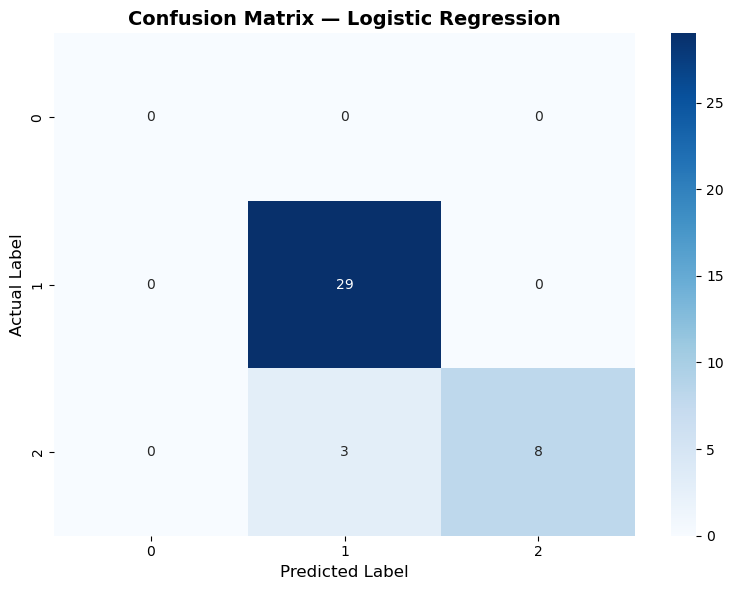

In [48]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
present_classes = sorted(np.unique(np.concatenate([y_test, y_train])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]
cm = confusion_matrix(y_test, y_pred, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)

plt.title("Confusion Matrix — Logistic Regression", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout();

In [49]:
print("Confusion Matrix:")
print(cm)
print(f"\nCorrect Predictions  : {cm.diagonal().sum()}")
print(f"Wrong Predictions    : {cm.sum() - cm.diagonal().sum()}")
print(f"Total Test Samples   : {cm.sum()}")

Confusion Matrix:
[[ 0  0  0]
 [ 0 29  0]
 [ 0  3  8]]

Correct Predictions  : 37
Wrong Predictions    : 3
Total Test Samples   : 40


### 2). DECISION TREE


In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
model_dt = DecisionTreeClassifier(random_state = 42)
model_dt.fit(x_train,y_train)
y_pred_dt = model_dt.predict(x_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_dt])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]
print("Classification Report:")
print(classification_report(y_test, y_pred_dt,
                            labels=present_classes,
                            target_names=class_names))

Accuracy: 77.50%
Classification Report:
              precision    recall  f1-score   support

           1       0.81      0.90      0.85        29
           2       0.62      0.45      0.53        11

    accuracy                           0.78        40
   macro avg       0.72      0.68      0.69        40
weighted avg       0.76      0.78      0.76        40



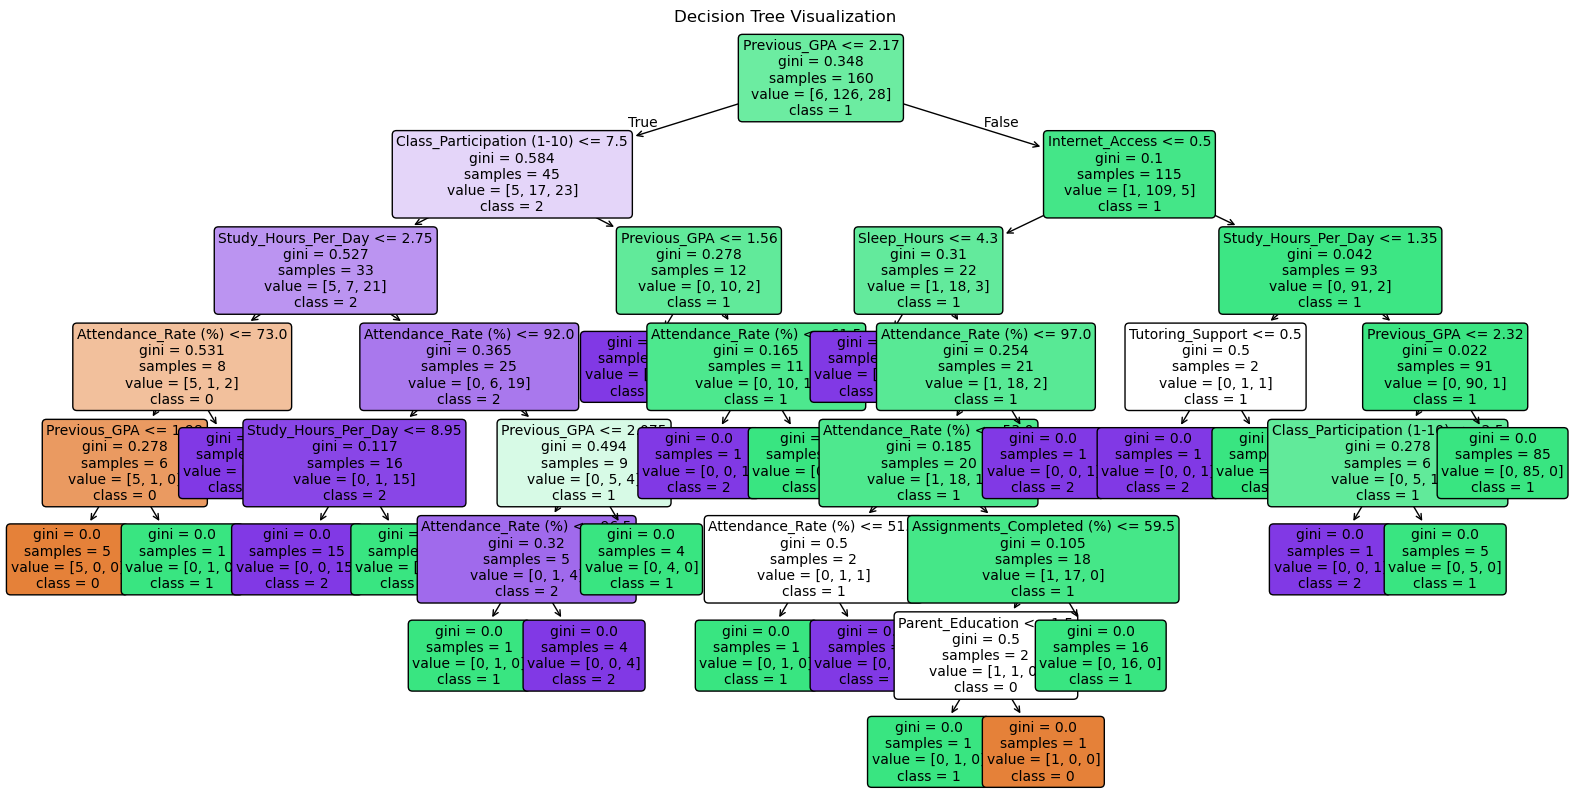

In [26]:
# Visualising Decision Tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))
plot_tree(model_dt,
          feature_names=x.columns.tolist(),
          class_names=[str(c) for c in le_target.classes_],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Decision Tree Visualization");


In [27]:
print("Model Comparison:")
print(f"Logistic Regression Accuracy : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Decision Tree Accuracy       : {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")

Model Comparison:
Logistic Regression Accuracy : 92.50%
Decision Tree Accuracy       : 77.50%


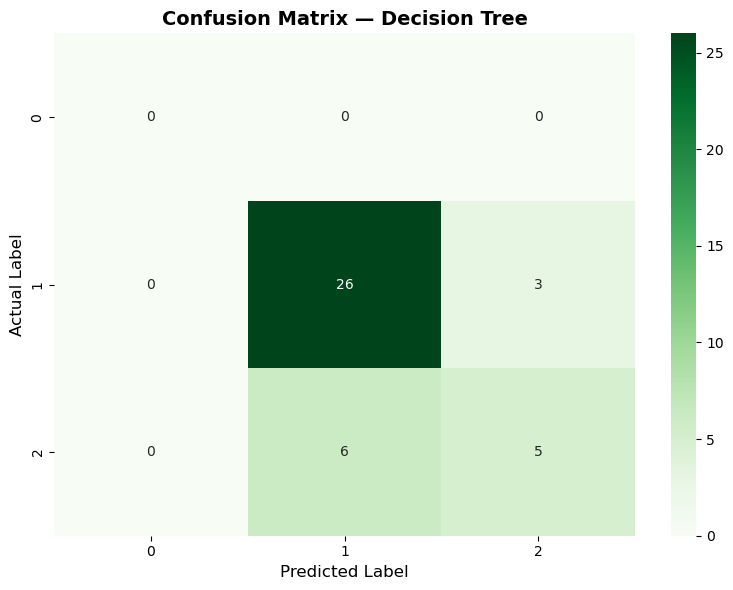

In [50]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_dt, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — Decision Tree", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout();

### 3). RANDOM FOREST 

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(x_train, y_train)
y_pred_rf = model_rf.predict(x_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf*100:.2f}%")
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]
print("Classification Report:")
print(classification_report(y_test, y_pred_rf,
                            labels=present_classes,
                            target_names=class_names))


Random Forest Accuracy: 85.00%
Classification Report:
              precision    recall  f1-score   support

           1       0.83      1.00      0.91        29
           2       1.00      0.45      0.62        11

    accuracy                           0.85        40
   macro avg       0.91      0.73      0.77        40
weighted avg       0.88      0.85      0.83        40



                      Feature  Importance
2                Previous_GPA    0.382996
0         Study_Hours_Per_Day    0.133156
4  Class_Participation (1-10)    0.113136
1         Attendance_Rate (%)    0.087178
3   Assignments_Completed (%)    0.079471
5                 Sleep_Hours    0.059904
6  Extracurricular_Activities    0.042743
7            Parent_Education    0.037394
8             Internet_Access    0.032478
9            Tutoring_Support    0.031543


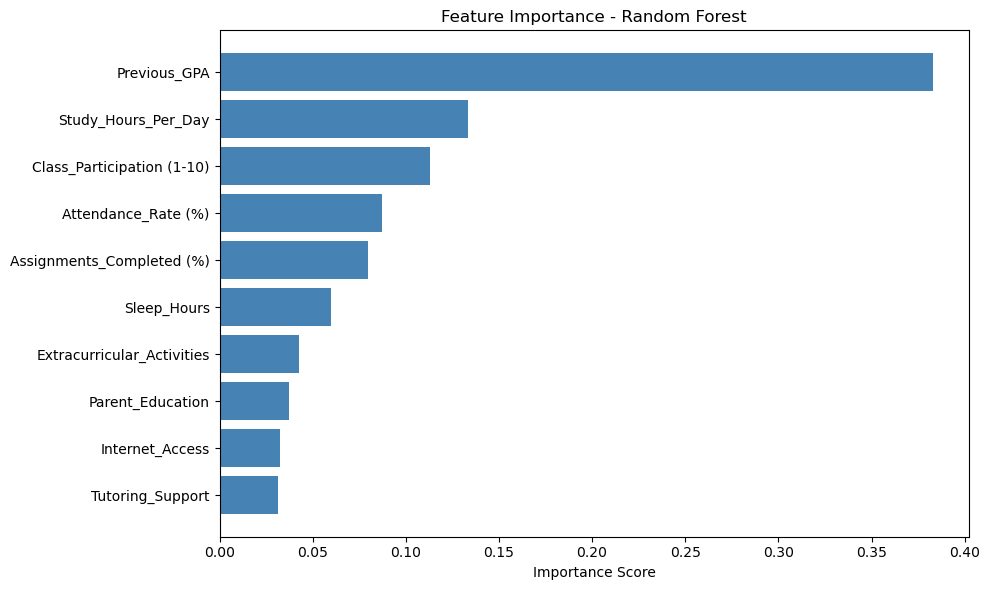

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': model_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], 
         feature_importance['Importance'], color='steelblue')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout();

In [30]:
print("Model Comparison:")
print(f"Logistic Regression Accuracy : {accuracy_score(y_test, y_pred)  * 100:.2f}%")
print(f"Random Forest Accuracy       : {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")

Model Comparison:
Logistic Regression Accuracy : 92.50%
Random Forest Accuracy       : 85.00%


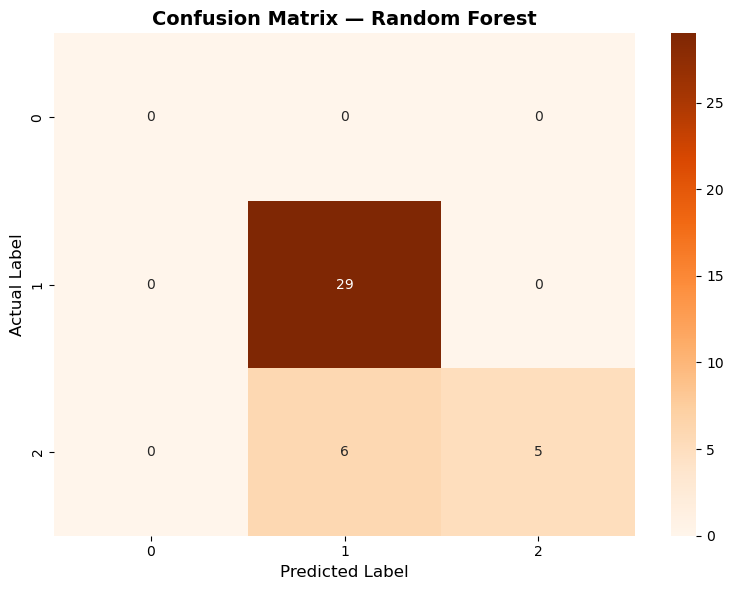

In [58]:
# Confusion Metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_rf, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — Random Forest", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 4). GRADIENT BOOSTING

In [31]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric="mlogloss",
)
xgb_model.fit(x_train, y_train)
y_pred_xgb=xgb_model.predict(x_test)
print("XGBoost Model trained succcessfully!")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb) * 100:.2f}%")

# Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_xgb])))
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred])))

print("Classification Report:")
print(classification_report(y_test, y_pred_xgb,
                            labels=present_classes,
                            target_names=class_names));

XGBoost Model trained succcessfully!
Accuracy: 85.00%
Classification Report:
              precision    recall  f1-score   support

           1       0.83      1.00      0.91        29
           2       1.00      0.45      0.62        11

    accuracy                           0.85        40
   macro avg       0.91      0.73      0.77        40
weighted avg       0.88      0.85      0.83        40



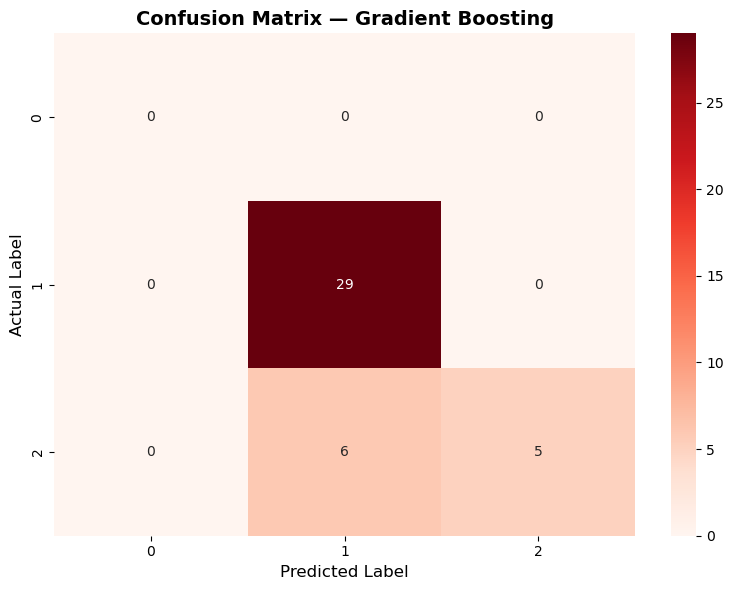

In [55]:
#  Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_xgb, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — Gradient Boosting", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout();

### 5). LightGBM

In [32]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Create the model
lgb_model = lgb.LGBMClassifier(
    random_state=42,
    verbose=-1,
    n_estimators=50,
    num_leaves=15,
    min_child_samples=5
)

# Train the model
lgb_model.fit(x_train, y_train)

# Make predictions
y_pred_lgb = lgb_model.predict(x_test)

# Evaluate
print(f"Accuracy: {accuracy_score(y_test, y_pred_lgb) * 100:.2f}%")

# Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_lgb])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("Classification Report:")
print(classification_report(y_test, y_pred_lgb,
                            labels=present_classes,
                            target_names=class_names))

Accuracy: 90.00%
Classification Report:
              precision    recall  f1-score   support

           1       0.88      1.00      0.94        29
           2       1.00      0.64      0.78        11

    accuracy                           0.90        40
   macro avg       0.94      0.82      0.86        40
weighted avg       0.91      0.90      0.89        40



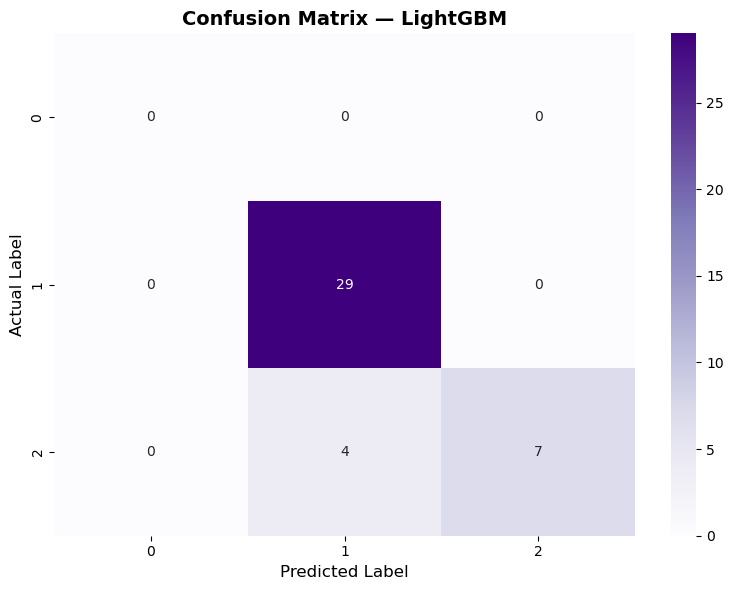

In [54]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_lgb, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — LightGBM", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 6). SUPPORT VECTORE MACHINE

In [33]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Step 1 — Create the model
model_svm = SVC(kernel='rbf', random_state=42)

# Step 2 — Train the model
model_svm.fit(x_train, y_train)

# Step 3 — Make predictions
y_pred_svm = model_svm.predict(x_test)

# Step 4 — Evaluate
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm) * 100:.2f}%")

# Step 5 — Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_svm])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm,
                            labels=present_classes,
                            target_names=class_names))

Accuracy: 72.50%

Classification Report:
              precision    recall  f1-score   support

           1       0.72      1.00      0.84        29
           2       0.00      0.00      0.00        11

    accuracy                           0.72        40
   macro avg       0.36      0.50      0.42        40
weighted avg       0.53      0.72      0.61        40



C:\Users\USER\anaconda3\envs\jupyter_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\USER\anaconda3\envs\jupyter_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\USER\anaconda3\envs\jupyter_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

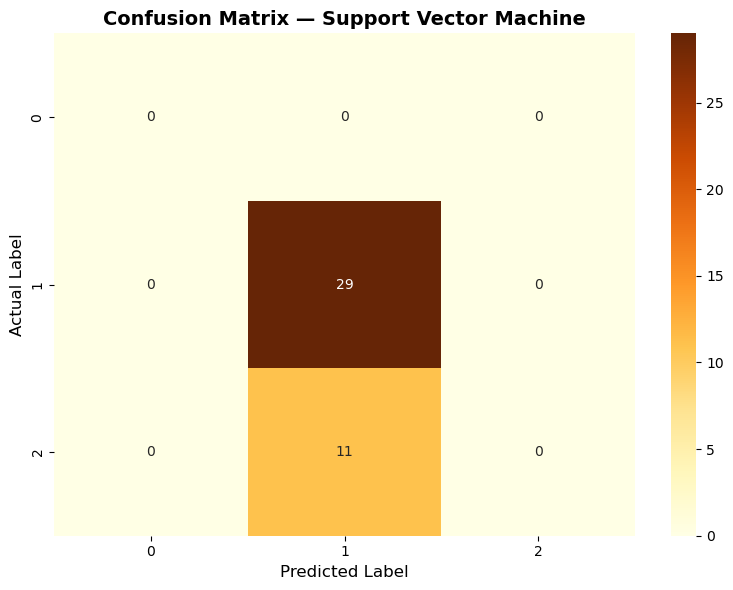

In [59]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_svm, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrBr',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — Support Vector Machine", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 7). KNN

In [34]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Create and train model
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train, y_train)

# Predictions
y_pred_knn = model_knn.predict(x_test)

# Accuracy
print(f"KNN Accuracy: {accuracy_score(y_test, y_pred_knn) * 100:.2f}%")

# Classification Report — zero_division=0 suppresses the warning
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_knn])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn,
                            labels=present_classes,
                            target_names=class_names,
                            zero_division=0))  # ← Add this

KNN Accuracy: 77.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.78      1.00      0.88        29
           2       1.00      0.18      0.31        11

    accuracy                           0.78        40
   macro avg       0.59      0.39      0.40        40
weighted avg       0.84      0.78      0.72        40



In [35]:
# Try different K values to find the best one
accuracy_scores = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    acc = accuracy_score(y_test, knn.predict(x_test))
    accuracy_scores.append(acc)
    print(f"K={k:2d}  Accuracy: {acc * 100:.2f}%")

best_k = accuracy_scores.index(max(accuracy_scores)) + 1
print(f"\nBest K: {best_k} with accuracy {max(accuracy_scores) * 100:.2f}%")

K= 1  Accuracy: 77.50%
K= 2  Accuracy: 70.00%
K= 3  Accuracy: 70.00%
K= 4  Accuracy: 72.50%
K= 5  Accuracy: 77.50%
K= 6  Accuracy: 72.50%
K= 7  Accuracy: 75.00%
K= 8  Accuracy: 72.50%
K= 9  Accuracy: 72.50%
K=10  Accuracy: 72.50%
K=11  Accuracy: 72.50%
K=12  Accuracy: 72.50%
K=13  Accuracy: 72.50%
K=14  Accuracy: 72.50%
K=15  Accuracy: 72.50%
K=16  Accuracy: 72.50%
K=17  Accuracy: 72.50%
K=18  Accuracy: 72.50%
K=19  Accuracy: 72.50%
K=20  Accuracy: 72.50%

Best K: 1 with accuracy 77.50%


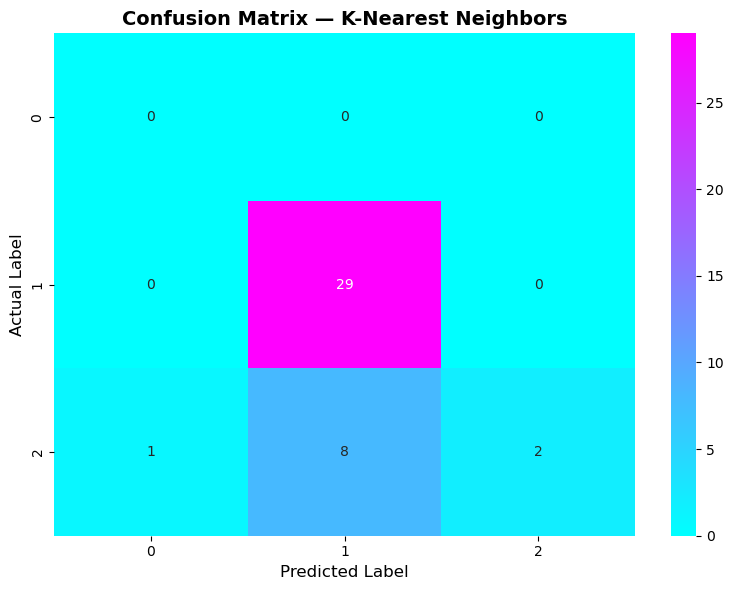

In [60]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_knn, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='cool',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — K-Nearest Neighbors", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 8). NAIVE BAYES(GAUSSIAN)

In [36]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Step 1 — Create the model
model_nb = GaussianNB()

# Step 2 — Train the model
model_nb.fit(x_train, y_train)

# Step 3 — Make predictions
y_pred_nb = model_nb.predict(x_test)

# Step 4 — Evaluate
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes Accuracy: {accuracy_nb * 100:.2f}%")

# Step 5 — Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_nb])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb,
                            labels=present_classes,
                            target_names=class_names,
                           zero_division=0))

Naive Bayes Accuracy: 82.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.88      0.97      0.92        29
           2       1.00      0.45      0.62        11

    accuracy                           0.82        40
   macro avg       0.62      0.47      0.51        40
weighted avg       0.91      0.82      0.84        40



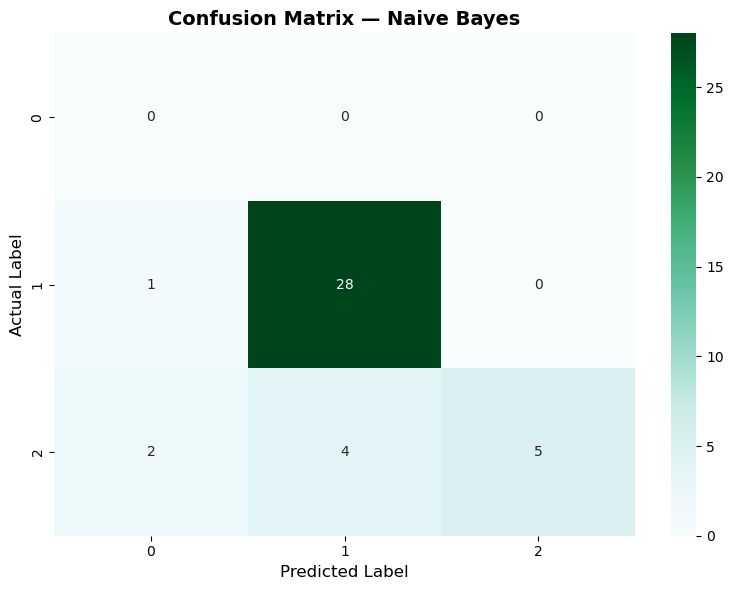

In [61]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_nb, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='BuGn',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — Naive Bayes", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 9). ADABOOST

In [37]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Step 1 — Create the model
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)

# Step 2 — Train the model
ada_model.fit(x_train, y_train)

# Step 3 — Make predictions
y_pred_ada = ada_model.predict(x_test)

# Step 4 — Evaluate
accuracy = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost Accuracy: {accuracy * 100:.2f}%")

# Step 5 — Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_ada])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada,
                            labels=present_classes,
                            target_names=class_names,
                           zero_division=0))

AdaBoost Accuracy: 77.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.83      0.86      0.85        29
           2       0.67      0.55      0.60        11

    accuracy                           0.78        40
   macro avg       0.50      0.47      0.48        40
weighted avg       0.79      0.78      0.78        40



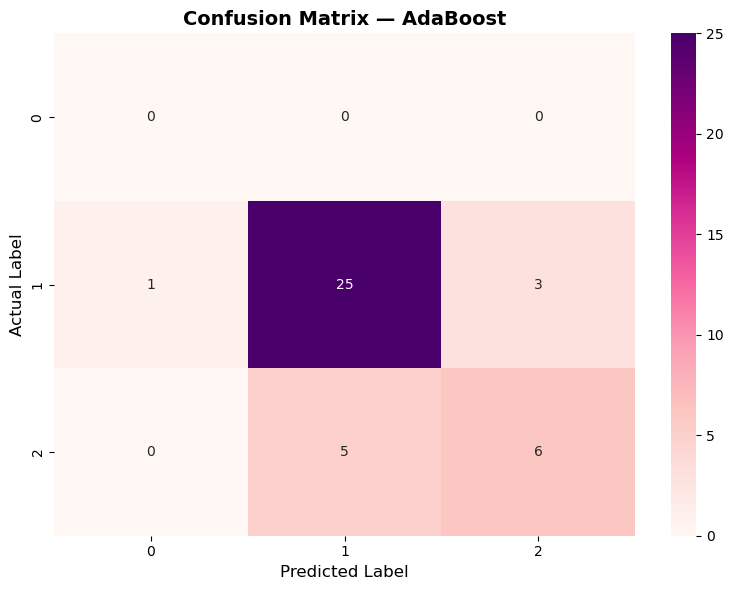

In [62]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_ada, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — AdaBoost", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

### 10). CATBOOST

In [38]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Create the model
model_catboost = CatBoostClassifier(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=0          # Suppress training logs
)

# Train the model
model_catboost.fit(x_train, y_train)

# Make predictions
y_pred_catboost = model_catboost.predict(x_test)

print("CatBoost Model trained successfully!")

CatBoost Model trained successfully!


In [39]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred_catboost)
print(f"Accuracy: {accuracy * 100:.2f}%")

y_pred_labels = np.argmax(y_pred_catboost, axis=1)

# Classification Report
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred_labels])))
class_names = [str(name) for name in le_target.inverse_transform(present_classes)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_catboost,
                            labels=present_classes,
                            target_names=class_names,
                           zero_division=0))

Accuracy: 85.00%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.83      1.00      0.91        29
           2       1.00      0.45      0.62        11

    accuracy                           0.85        40
   macro avg       0.61      0.48      0.51        40
weighted avg       0.88      0.85      0.83        40



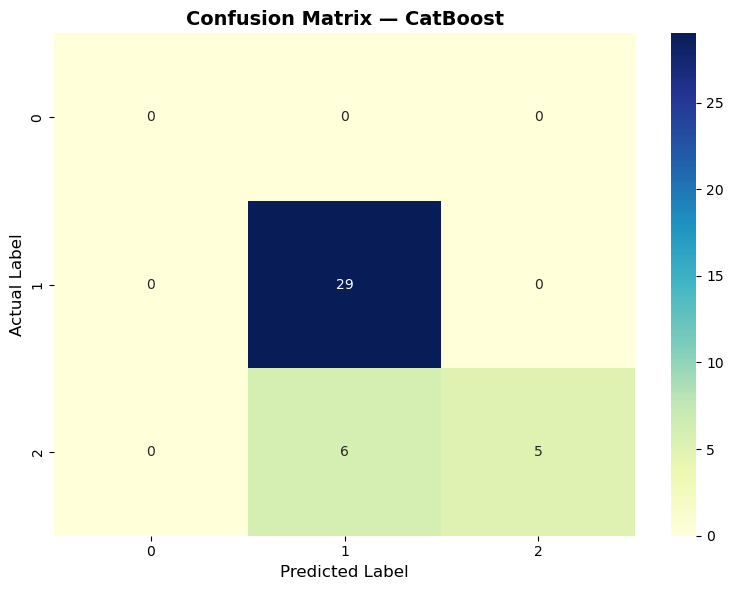

In [64]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred_catboost, labels=present_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title("Confusion Matrix — CatBoost", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()
plt.show()

## TASK 4

In [67]:
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# ✅ All imports needed
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier        # ✅ LightGBM
from catboost import CatBoostClassifier    # ✅ CatBoost

# Define all models
models_summary = {
    "Logistic Regression" : LogisticRegression(max_iter=5000, random_state=42),
    "Decision Tree"        : DecisionTreeClassifier(random_state=42),
    "Random Forest"        : RandomForestClassifier(n_estimators=100, random_state=42),
    "LightGBM"             : LGBMClassifier(random_state=42, verbose=-1, n_estimators=50, num_leaves=15, min_child_samples=5),
    "Gradient Boosting"    : GradientBoostingClassifier(n_estimators=100, random_state=42),
    "SVM"                  : SVC(random_state=42),
    "KNN"                  : KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes"          : GaussianNB(),
    "AdaBoost"             : AdaBoostClassifier(n_estimators=100, random_state=42),
    "CatBoost"             : CatBoostClassifier(iterations=1000, random_state=42, verbose=0),
}

# Store results
results = []

for name, model in models_summary.items():

    # Measure training time
    start = time.time()
    model.fit(x_train, y_train)
    end = time.time()
    training_time = round(end - start, 4)

    # Predictions
    y_pred_temp = model.predict(x_test)

    # Metrics
    accuracy = round(accuracy_score(y_test, y_pred_temp) * 100, 2)
    macro_f1 = round(f1_score(y_test, y_pred_temp, average='macro'), 4)

    results.append({
        "Algorithm"        : name,
        "Accuracy (%)"     : accuracy,
        "Macro F1-Score"   : macro_f1,
        "Training Time (s)": training_time
    })

    print(f"✅ {name} — Accuracy: {accuracy}% | Macro F1: {macro_f1} | Time: {training_time}s")

# Create Summary DataFrame
summary_df = pd.DataFrame(results)
summary_df = summary_df.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
summary_df.index += 1

# Display Table
print("\n")
print("=" * 65)
print("          COMPARATIVE SUMMARY TABLE")
print("=" * 65)
print(summary_df.to_string(index=True))
print("=" * 65)
print(f"\n🏆 Best Model   : {summary_df.iloc[0]['Algorithm']}")
print(f"   Accuracy     : {summary_df.iloc[0]['Accuracy (%)']}%")
print(f"   Macro F1     : {summary_df.iloc[0]['Macro F1-Score']}")
print(f"   Training Time: {summary_df.iloc[0]['Training Time (s)']}s")

✅ Logistic Regression — Accuracy: 92.5% | Macro F1: 0.8965 | Time: 0.4992s
✅ Decision Tree — Accuracy: 77.5% | Macro F1: 0.6894 | Time: 0.0112s
✅ Random Forest — Accuracy: 85.0% | Macro F1: 0.7656 | Time: 0.2203s
✅ LightGBM — Accuracy: 90.0% | Macro F1: 0.8566 | Time: 0.0698s
✅ Gradient Boosting — Accuracy: 82.5% | Macro F1: 0.7386 | Time: 0.5256s
✅ SVM — Accuracy: 72.5% | Macro F1: 0.4203 | Time: 0.0085s
✅ KNN — Accuracy: 77.5% | Macro F1: 0.3955 | Time: 0.0057s
✅ Naive Bayes — Accuracy: 82.5% | Macro F1: 0.5143 | Time: 0.0s
✅ AdaBoost — Accuracy: 77.5% | Macro F1: 0.4825 | Time: 0.2299s
✅ CatBoost — Accuracy: 85.0% | Macro F1: 0.7656 | Time: 1.8093s


          COMPARATIVE SUMMARY TABLE
              Algorithm  Accuracy (%)  Macro F1-Score  Training Time (s)
1   Logistic Regression          92.5          0.8965             0.4992
2              LightGBM          90.0          0.8566             0.0698
3              CatBoost          85.0          0.7656             1.8093
4         